In [1]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.visualization import make_lupton_rgb
from photutils.segmentation import (SourceCatalog, deblend_sources, detect_sources, detect_threshold)
from astropy.io import fits
from astropy import units as u 
from astropy.visualization import ZScaleInterval
from astropy.coordinates import SkyCoord

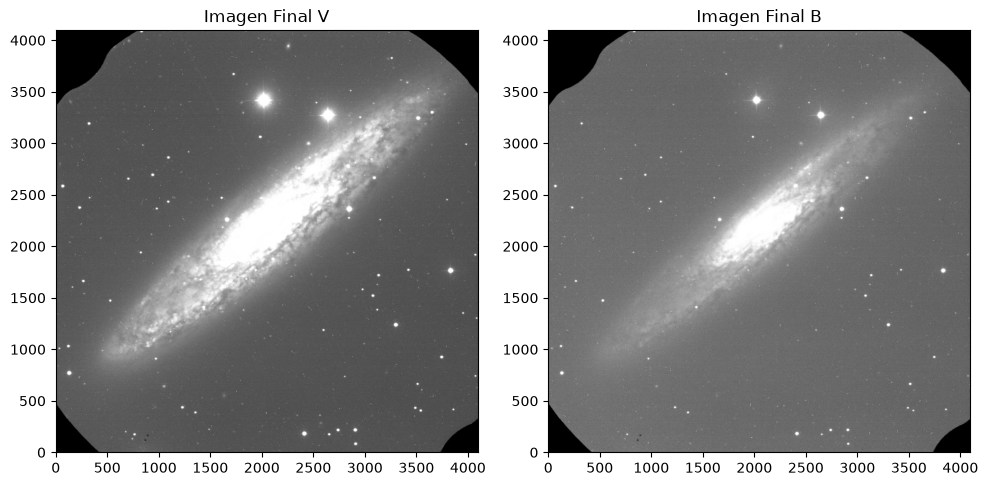

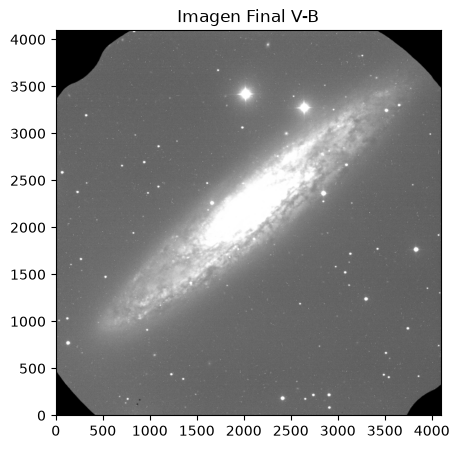

In [4]:
img_v = fits.open('Img_V.fits')[0].data 
img_b = fits.open('Img_B.fits')[0].data

img_prom = np.median([img_v, img_b], axis=0)

# IMÁGENES FINALES FILTROS V Y B
fig, ax = plt.subplots(1, 2, figsize=(10, 5))

zscale_b = ZScaleInterval(contrast=0.25)
min_value, max_value = zscale_b.get_limits(img_v)
ax[0].imshow(img_v, vmin=min_value, vmax=max_value, cmap='gray', origin='lower')
ax[0].set_title('Imagen Final V')

zscale_b = ZScaleInterval(contrast=0.25)
min_value, max_value = zscale_b.get_limits(img_b)
ax[1].imshow(img_b, vmin=min_value, vmax=max_value, cmap='gray', origin='lower')
ax[1].set_title('Imagen Final B')

plt.tight_layout()
plt.show()

# IMAGEN FINAL V-B
fig = plt.figure(figsize=(5, 5))
zscale_b = ZScaleInterval(contrast=0.25)
min_value, max_value = zscale_b.get_limits(img_prom)

plt.imshow(img_prom, vmin=min_value, vmax=max_value, cmap='gray', origin='lower')
plt.title('Imagen Final V-B')
plt.show()

In [10]:
# Restamos el fondo de cada imagen
v_fondo = img_v - np.nanmedian(img_v)
b_fondo = img_b - np.nanmedian(img_b)
prom_fondo = img_prom - np.nanmedian(img_prom)

# Normalizamos cada canal por su percentil 99.5
v_norm = v_fondo / np.nanpercentile(v_fondo, 99.5)
b_norm = b_fondo / np.nanpercentile(b_fondo, 99.5)
prom_norm = prom_fondo / np.nanpercentile(prom_fondo, 99.5)

# Evitamos valores negativos y extremos
v_norm = np.clip(v_norm, 0, 1.2)
b_norm = np.clip(b_norm, 0, 1.2)
prom_norm = np.clip(prom_norm, 0, 1.2)

# Composición RGB de NGC 253
imagen = make_lupton_rgb(
    v_norm,
    prom_norm,
    b_norm,
    minimum=0,
    Q=8,
    stretch=0.5,
    filename="NGC253_RGB.jpeg"
)

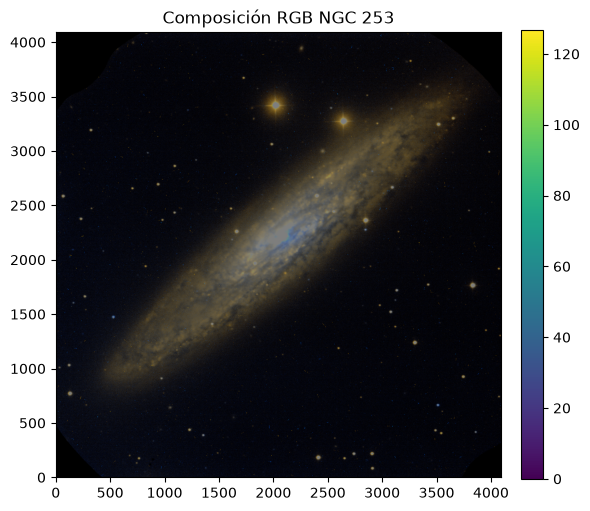

In [12]:
zscale_v = ZScaleInterval(contrast=0.25)
vmin, vmax = zscale_v.get_limits(imagen)

fig, ax = plt.subplots(figsize=(6,6))
ax.imshow(imagen, origin='lower', vmin=vmin, vmax=vmax)
ax.set_title('Composición RGB NGC 253')

#Luminancia, brillo promedio del RGB, para colorbar
luminancia = np.mean(imagen, axis=2)
norm = plt.Normalize(vmin=np.min(luminancia), vmax=np.max(luminancia))
sm = plt.cm.ScalarMappable(norm=norm, cmap='viridis')
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax, orientation='vertical', fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()